In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [5]:
df1=pd.read_csv('Unemployment in India.csv')
df2=pd.read_csv('Unemployment_Rate_upto_11_2020.csv')

In [13]:
df1

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
...,...,...,...,...,...,...,...
763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
766,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
df1.isna().sum()

Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

In [15]:
df1 = df1.dropna()

In [16]:
df1

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
...,...,...,...,...,...,...,...
749,West Bengal,29-02-2020,Monthly,7.55,10871168.0,44.09,Urban
750,West Bengal,31-03-2020,Monthly,6.67,10806105.0,43.34,Urban
751,West Bengal,30-04-2020,Monthly,15.63,9299466.0,41.20,Urban
752,West Bengal,31-05-2020,Monthly,15.22,9240903.0,40.67,Urban


In [17]:
df1.isna().sum()

Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Area                                        0
dtype: int64

In [18]:
df1.dtypes

Region                                          str
 Date                                           str
 Frequency                                      str
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                            str
dtype: object

In [12]:
df2

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.740
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.740
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.740
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.740
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.740
...,...,...,...,...,...,...,...,...,...
262,West Bengal,30-06-2020,M,7.29,30726310,40.39,East,22.9868,87.855
263,West Bengal,31-07-2020,M,6.83,35372506,46.17,East,22.9868,87.855
264,West Bengal,31-08-2020,M,14.87,33298644,47.48,East,22.9868,87.855
265,West Bengal,30-09-2020,M,9.35,35707239,47.73,East,22.9868,87.855


In [35]:
df2.dtypes

Region                                                 str
 Date                                       datetime64[us]
 Frequency                                             str
 Estimated Unemployment Rate (%)                   float64
 Estimated Employed                                  int64
 Estimated Labour Participation Rate (%)           float64
Region.1                                               str
longitude                                          float64
latitude                                           float64
dtype: object

In [9]:
df2.isna().sum()

Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0
dtype: int64

In [19]:
df1.shape

(740, 7)

In [20]:
df2.shape

(267, 9)

In [21]:
df1.columns

Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='str')

In [22]:
df2.columns

Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Region.1', 'longitude', 'latitude'],
      dtype='str')

In [23]:
df1

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
...,...,...,...,...,...,...,...
749,West Bengal,29-02-2020,Monthly,7.55,10871168.0,44.09,Urban
750,West Bengal,31-03-2020,Monthly,6.67,10806105.0,43.34,Urban
751,West Bengal,30-04-2020,Monthly,15.63,9299466.0,41.20,Urban
752,West Bengal,31-05-2020,Monthly,15.22,9240903.0,40.67,Urban


In [24]:
df2

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.740
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.740
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.740
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.740
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.740
...,...,...,...,...,...,...,...,...,...
262,West Bengal,30-06-2020,M,7.29,30726310,40.39,East,22.9868,87.855
263,West Bengal,31-07-2020,M,6.83,35372506,46.17,East,22.9868,87.855
264,West Bengal,31-08-2020,M,14.87,33298644,47.48,East,22.9868,87.855
265,West Bengal,30-09-2020,M,9.35,35707239,47.73,East,22.9868,87.855


In [34]:
df1[' Date'] = pd.to_datetime(df[' Date'], dayfirst=True)
df2[' Date'] = pd.to_datetime(df[' Date'], dayfirst=True)

In [43]:
print("\nRegion count:", df1['Region'].nunique())
print("Regions:", df1['Region'].unique())


Region count: 28
Regions: <ArrowStringArray>
[  'Andhra Pradesh',            'Assam',            'Bihar',
     'Chhattisgarh',            'Delhi',              'Goa',
          'Gujarat',          'Haryana', 'Himachal Pradesh',
  'Jammu & Kashmir',        'Jharkhand',        'Karnataka',
           'Kerala',   'Madhya Pradesh',      'Maharashtra',
        'Meghalaya',           'Odisha',       'Puducherry',
           'Punjab',        'Rajasthan',           'Sikkim',
       'Tamil Nadu',        'Telangana',          'Tripura',
    'Uttar Pradesh',      'Uttarakhand',      'West Bengal',
       'Chandigarh']
Length: 28, dtype: str


In [44]:
print("Dataset shape:", df1.shape)
print("Date range:", df1[' Date'].min().date(), "→", df1[' Date'].max().date())
print("Number of regions:", df1['Region'].nunique())
print(df1.describe())

Dataset shape: (740, 7)
Date range: 2019-05-31 → 2020-10-31
Number of regions: 28
                      Date  Estimated Unemployment Rate (%)  \
count                  480                       740.000000   
mean   2020-02-08 07:33:00                        11.787946   
min    2019-05-31 00:00:00                         0.000000   
25%    2019-09-30 00:00:00                         4.657500   
50%    2020-01-31 00:00:00                         8.350000   
75%    2020-06-30 00:00:00                        15.887500   
max    2020-10-31 00:00:00                        76.740000   
std                    NaN                        10.721298   

       Estimated Employed  Estimated Labour Participation Rate (%)  
count        7.400000e+02                               740.000000  
mean         7.204460e+06                                42.630122  
min          4.942000e+04                                13.330000  
25%          1.190404e+06                                38.062500  
50%  

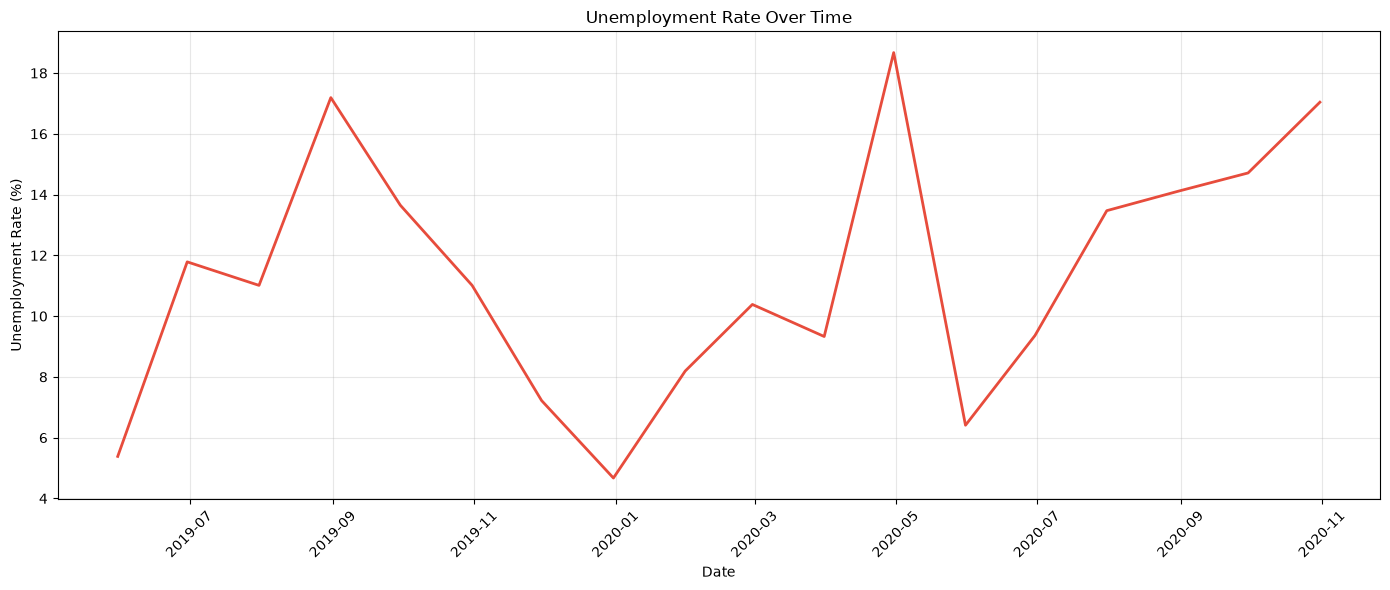

In [45]:
plt.figure(figsize=(14, 6))
plt.plot(df1.groupby(' Date')[' Estimated Unemployment Rate (%)'].mean(), 
         color='#e74c3c', linewidth=2)
plt.title('Unemployment Rate Over Time')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

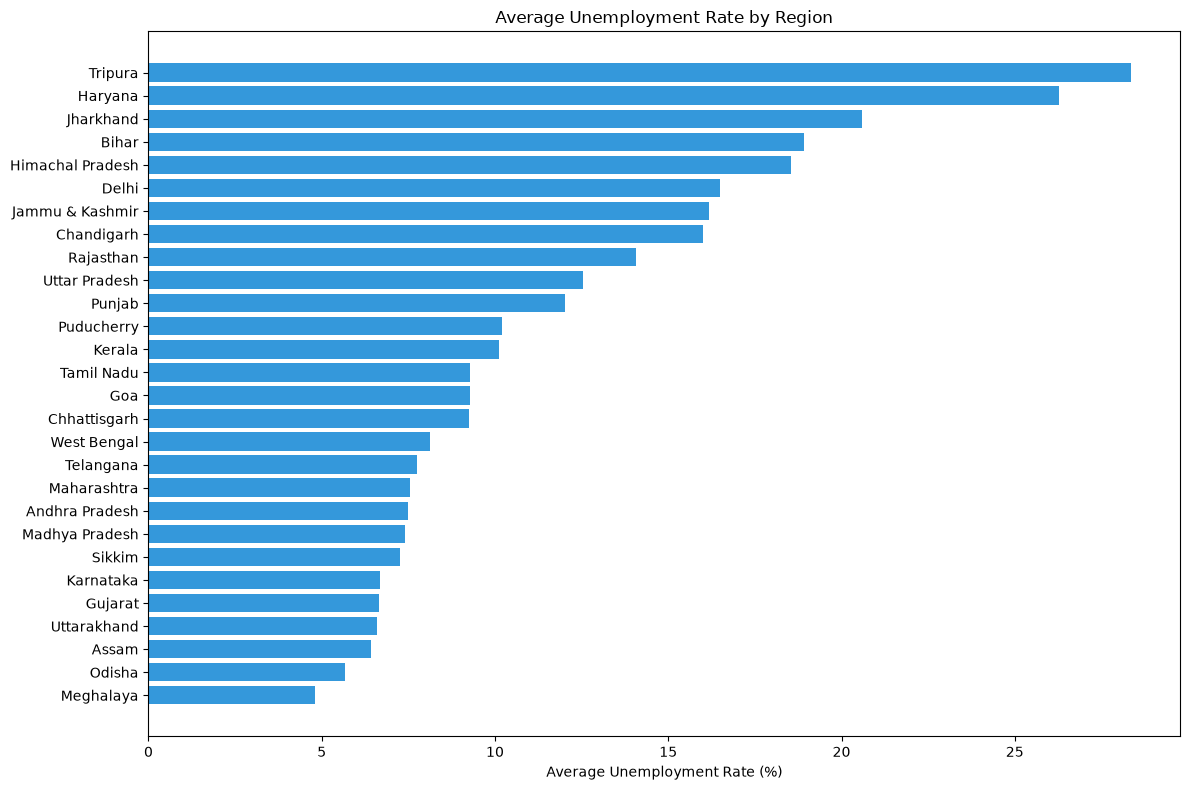

In [46]:
region_avg = df1.groupby('Region')[' Estimated Unemployment Rate (%)'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 8))
plt.barh(region_avg.index, region_avg.values, color='#3498db')
plt.xlabel('Average Unemployment Rate (%)')
plt.title('Average Unemployment Rate by Region')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [47]:
covid_start = pd.Timestamp('2020-03-01')

before_covid = df1[df1[' Date'] < covid_start][' Estimated Unemployment Rate (%)'].mean()
after_covid = df1[df1[' Date'] >= covid_start][' Estimated Unemployment Rate (%)'].mean()

print(f"Before Covid-19: {before_covid:.2f}%")
print(f"After Covid-19: {after_covid:.2f}%")
print(f"Increase: +{after_covid - before_covid:.2f}%")

Before Covid-19: 10.04%
After Covid-19: 13.07%
Increase: +3.03%


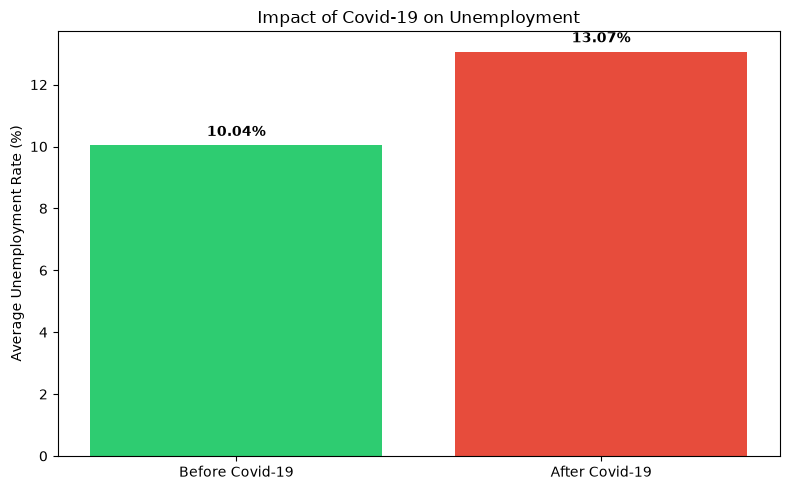

In [48]:
plt.figure(figsize=(8, 5))
bars = plt.bar(['Before Covid-19', 'After Covid-19'],
               [before_covid, after_covid],
               color=['#2ecc71', '#e74c3c'])
plt.ylabel('Average Unemployment Rate (%)')
plt.title('Impact of Covid-19 on Unemployment')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.3,
             f'{height:.2f}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

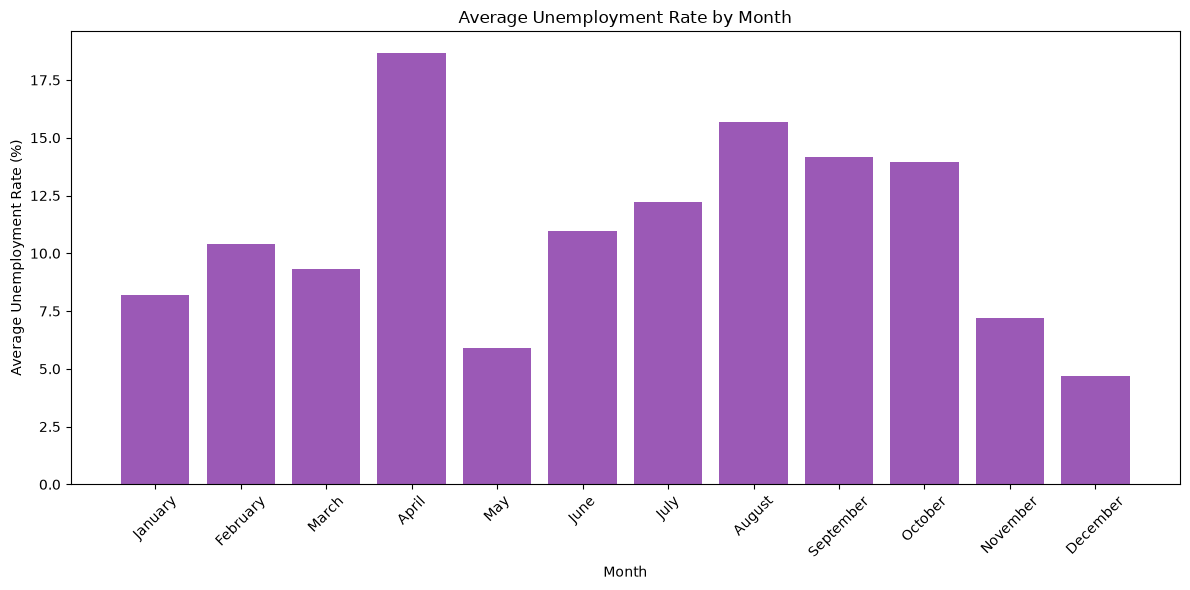

In [49]:
df1['Month'] = df1[' Date'].dt.month_name()

monthly_avg = df1.groupby('Month')[' Estimated Unemployment Rate (%)'].mean().reindex(
    ['January','February','March','April','May','June',
     'July','August','September','October','November','December']
).dropna()

plt.figure(figsize=(12, 6))
plt.bar(monthly_avg.index, monthly_avg.values, color='#9b59b6')
plt.title('Average Unemployment Rate by Month')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

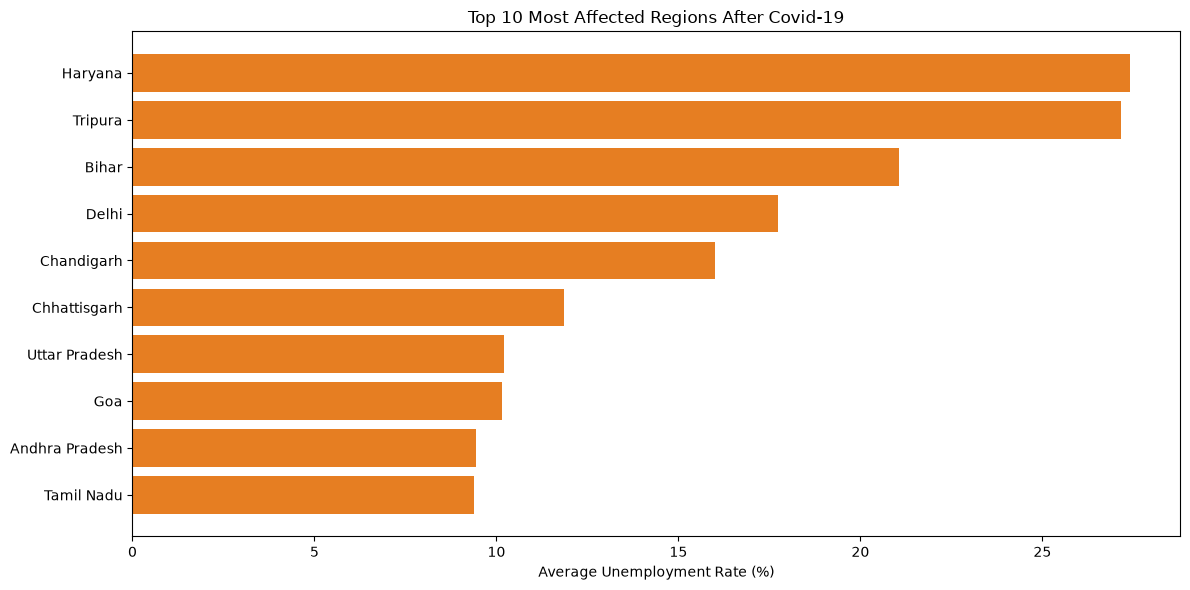

In [50]:
covid_impact = df1[df1[' Date'] >= covid_start].groupby('Region')[' Estimated Unemployment Rate (%)'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
plt.barh(covid_impact.index, covid_impact.values, color='#e67e22')
plt.xlabel('Average Unemployment Rate (%)')
plt.title('Top 10 Most Affected Regions After Covid-19')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [51]:
print("="*60)
print("TASK 2: UNEMPLOYMENT ANALYSIS - RESULTS")
print("="*60)
print(f"Dataset period: {df1[' Date'].min().date()} → {df1[' Date'].max().date()}")
print(f"Overall average unemployment: {df1[' Estimated Unemployment Rate (%)'].mean():.2f}%")
print(f"Before Covid-19: {before_covid:.2f}%")
print(f"After Covid-19: {after_covid:.2f}%")
print(f"Increase: +{after_covid - before_covid:.2f}%")
print(f"Highest unemployment region: {region_avg.index[0]} ({region_avg.values[0]:.2f}%)")
print(f"Lowest unemployment region: {region_avg.index[-1]} ({region_avg.values[-1]:.2f}%)")
print("="*60)

TASK 2: UNEMPLOYMENT ANALYSIS - RESULTS
Dataset period: 2019-05-31 → 2020-10-31
Overall average unemployment: 11.79%
Before Covid-19: 10.04%
After Covid-19: 13.07%
Increase: +3.03%
Highest unemployment region: Tripura (28.35%)
Lowest unemployment region: Meghalaya (4.80%)


### insights

KEY INSIGHTS AND RECOMMENDATIONS:

1. Covid-19 had a significant impact on unemployment. From March 2020,
   the unemployment rate increased sharply.

2. The most affected regions were urban areas, as these have a higher
   concentration of workers in the service sector.

3. Monthly analysis shows that unemployment peaked in April-May,
   then gradually declined.

4. Recommendations:
   - Support programs for small businesses during Covid
   - Increase unemployment benefits
   - Government investments to create new jobs
   - Digital skills training programs